# Computação Gráfica: fundamentos, aplicações e diagnóstico de erros

**Escopo:** aulas 1 a 10 — representação de objetos, propriedades, transformações geométricas, composição de cenas, câmera, projeção e animação.

Este notebook combina conceitos teóricos, aplicações, exemplos executáveis e situações de erro frequentes. Os exemplos usam `NumPy` e `Matplotlib` para permitir experimentação.

## Objetivos de aprendizagem

- distinguir representação geométrica, propriedades e aparência;
- aplicar translação, rotação e escala com coordenadas homogêneas;
- compor objetos por uma hierarquia local-mundo-câmera;
- explicar projeção ortográfica e perspectiva;
- construir animações dependentes de tempo;
- reconhecer erros de ordem, unidades, pivôs, matrizes e atualização temporal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['axes.grid'] = True

def homog(vertices):
    vertices = np.asarray(vertices, dtype=float)
    return np.vstack([vertices, np.ones(vertices.shape[1])])

def aplicar(M, vertices):
    r = M @ homog(vertices)
    return r[:2] / r[2]

def plotar(ax, vertices, **kwargs):
    v = np.hstack([vertices, vertices[:, :1]])
    ax.plot(v[0], v[1], **kwargs)
print('Ambiente preparado.')

ModuleNotFoundError: No module named 'matplotlib'

## 1. Representação de objetos

Um objeto pode ser representado por pontos, segmentos, polígonos, malhas, superfícies paramétricas ou primitivas compostas. Em uma representação poligonal, vértices armazenam posições e índices definem arestas ou faces.

**Aplicações:** modelos OBJ, personagens articulados, edifícios, carros e elementos de uma caverna.

**Caso de erro:** vértices repetidos, índices inexistentes ou ordem inconsistente podem produzir faces degeneradas, buracos ou normais invertidas.

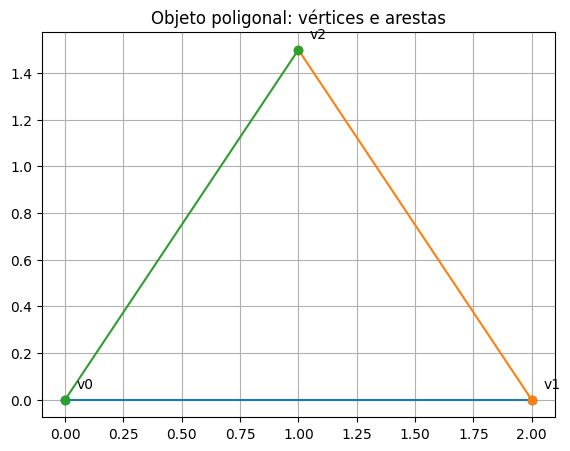

In [ ]:
triangulo = np.array([[0., 2., 1.], [0., 0., 1.5]])
arestas = [(0,1), (1,2), (2,0)]
fig, ax = plt.subplots()
for i,j in arestas:
    ax.plot([triangulo[0,i], triangulo[0,j]], [triangulo[1,i], triangulo[1,j]], 'o-')
for i,(x,y) in enumerate(triangulo.T): ax.text(x+.05,y+.05,f'v{i}')
ax.set_aspect('equal'); ax.set_title('Objeto poligonal: vértices e arestas'); plt.show()

## 2. Propriedades dos objetos

Além da geometria, um objeto possui posição, orientação, escala, cor, material, visibilidade, nome e relações hierárquicas. Separar geometria de estado permite reutilizar a mesma malha em várias instâncias.

In [ ]:
@dataclass
class Objeto2D:
    nome: str
    vertices: np.ndarray
    posicao: np.ndarray
    escala: float = 1.0
    angulo: float = 0.0
    cor: str = 'tab:blue'
    visivel: bool = True
objeto = Objeto2D('triângulo', triangulo, np.array([2.,1.]), 1.2, 20, 'tab:orange')
print(objeto)

Objeto2D(nome='triângulo', vertices=array([[0. , 2. , 1. ],
       [0. , 0. , 1.5]]), posicao=array([2., 1.]), escala=1.2, angulo=20, cor='tab:orange', visivel=True)


## 3. Transformações geométricas

Coordenadas homogêneas permitem representar translação, rotação e escala com matrizes 3×3. A ordem importa: **escala → rotação → translação** cria o objeto no espaço local, orienta-o e depois o coloca no mundo.

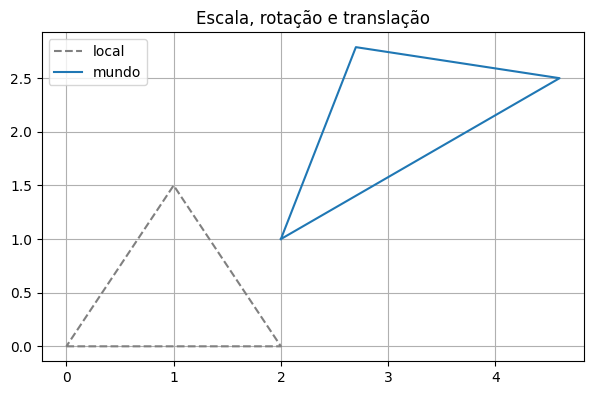

In [ ]:
def T(tx,ty): return np.array([[1,0,tx],[0,1,ty],[0,0,1.]],float)
def S(sx,sy): return np.array([[sx,0,0],[0,sy,0],[0,0,1.]],float)
def R(graus):
    a=np.deg2rad(graus); c,s=np.cos(a),np.sin(a)
    return np.array([[c,-s,0],[s,c,0],[0,0,1.]],float)
M = T(2,1) @ R(30) @ S(1.5,.8)
transformado = aplicar(M, triangulo)
fig,ax=plt.subplots(); plotar(ax,triangulo,label='local',color='gray',linestyle='--'); plotar(ax,transformado,label='mundo',color='tab:blue')
ax.set_aspect('equal'); ax.legend(); ax.set_title('Escala, rotação e translação'); plt.show()

### Caso de erro: ordem das transformações

Compare `T @ R` com `R @ T`. A primeira gira no espaço local e depois desloca; a segunda desloca e, ao girar, também gira a posição do objeto em torno da origem global. O sintoma é uma órbita ou posição inesperada.

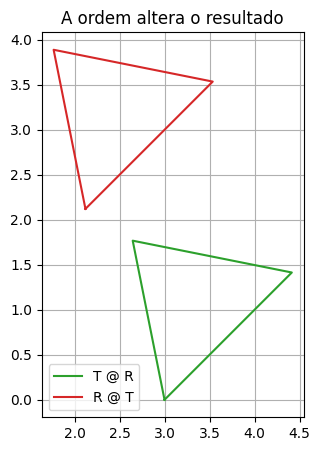

In [ ]:
certo=aplicar(T(3,0)@R(45),triangulo); surpresa=aplicar(R(45)@T(3,0),triangulo)
fig,ax=plt.subplots(); plotar(ax,certo,label='T @ R',color='tab:green'); plotar(ax,surpresa,label='R @ T',color='tab:red')
ax.set_aspect('equal'); ax.legend(); ax.set_title('A ordem altera o resultado'); plt.show()

## 4. Composição de objetos e hierarquia

Cenas complexas são construídas com objetos simples: um carro tem carroceria e rodas; um corpo humano tem tronco, braços, pernas e cabeça. Na hierarquia, `mundo_filho = mundo_pai @ local_filho` faz a transformação do pai afetar os filhos.

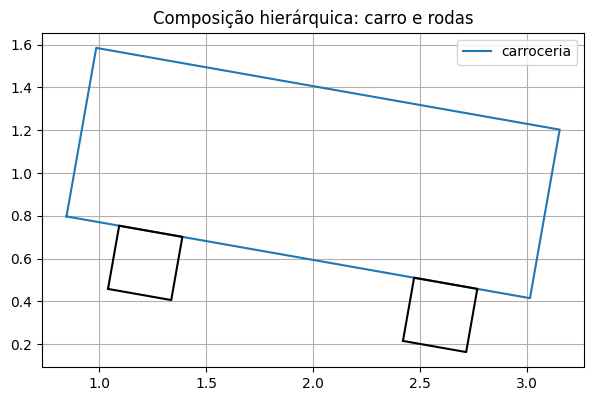

In [ ]:
quadrado=np.array([[-.5,.5,.5,-.5],[-.5,-.5,.5,.5]])
mundo_carro=T(2,1)@R(-10)
fig,ax=plt.subplots(); plotar(ax,aplicar(mundo_carro@S(2.2,.8),quadrado),color='tab:blue',label='carroceria')
for x in [-.7,.7]: plotar(ax,aplicar(mundo_carro@T(x,-.55)@S(.3,.3),quadrado),color='black')
ax.set_aspect('equal'); ax.legend(); ax.set_title('Composição hierárquica: carro e rodas'); plt.show()

**Erros frequentes:** aplicar a transformação do mundo duas vezes, esquecer o pivô local, atualizar o filho antes do pai ou misturar graus e radianos. Mantenha explicitamente as matrizes `local`, `mundo` e `câmera`.

## 5. Câmera e projeção

A câmera define como o mundo é observado. A transformação de visualização converte coordenadas do mundo para coordenadas relativas à câmera. A projeção ortográfica preserva tamanhos aparentes; a perspectiva faz objetos distantes parecerem menores.

Para uma câmera 2D simples: `p_câmera = T(-câmera_x, -câmera_y) p_mundo`.

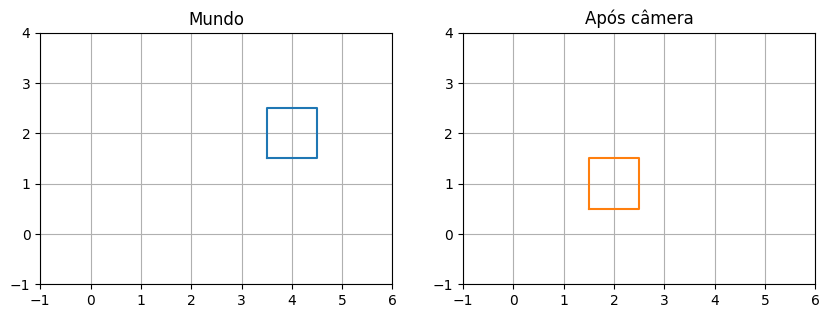

In [ ]:
mundo=aplicar(T(4,2),quadrado); camera=aplicar(T(-2,-1),mundo)
fig,axes=plt.subplots(1,2,figsize=(10,4)); plotar(axes[0],mundo,color='tab:blue'); axes[0].set_title('Mundo'); plotar(axes[1],camera,color='tab:orange'); axes[1].set_title('Após câmera')
for ax in axes: ax.set_aspect('equal'); ax.set_xlim(-1,6); ax.set_ylim(-1,4)
plt.show()

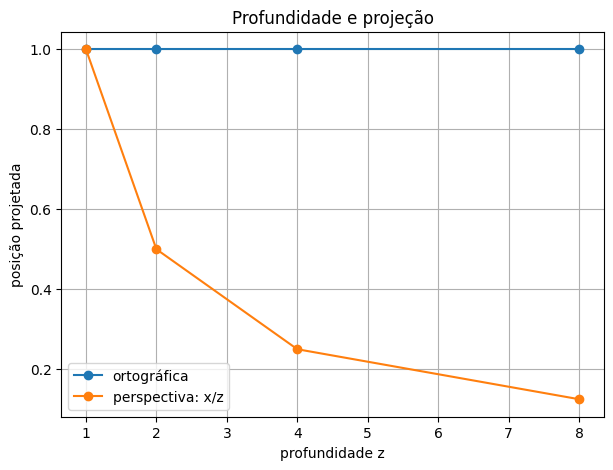

In [ ]:
z=np.array([1,2,4,8.]); x=np.ones_like(z)
plt.plot(z,x,'o-',label='ortográfica'); plt.plot(z,x/z,'o-',label='perspectiva: x/z')
plt.xlabel('profundidade z'); plt.ylabel('posição projetada'); plt.legend(); plt.title('Profundidade e projeção'); plt.show()

**Casos de erro:** câmera olhando na direção errada, vetor `up` paralelo à visão, divisão por profundidade próxima de zero, plano de recorte incorreto e confusão entre graus e radianos. Os sintomas incluem cena vazia, invertida, distorcida ou objetos desaparecendo.

## 6. Animação baseada em tempo

Uma animação robusta usa o intervalo de tempo `Δt`, não a quantidade de quadros: `p_novo = p_atual + v Δt` e `θ_novo = θ_atual + ω Δt`. Assim, a velocidade não depende da taxa de atualização.

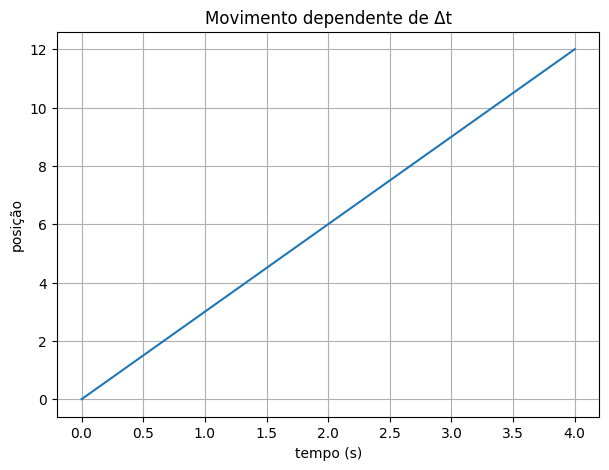

In [ ]:
velocidade=3.0; tempos=np.linspace(0,4,100); posicao=velocidade*tempos
plt.plot(tempos,posicao); plt.xlabel('tempo (s)'); plt.ylabel('posição'); plt.title('Movimento dependente de Δt'); plt.show()

Em Pygame, o padrão é obter `dt`, processar eventos, atualizar estados e desenhar. Teclas podem iniciar, pausar, reiniciar ou alternar animações previamente programadas.

```python
dt = relogio.tick(60) / 1000.0
for evento in pygame.event.get():
    if evento.type == pygame.KEYDOWN and evento.key == pygame.K_SPACE:
        pausado = not pausado
if not pausado:
    angulo += velocidade_angular * dt
```

**Erros:** usar `angulo += 1` por quadro, atualizar duas vezes, esquecer limites, não reiniciar todos os estados ou não processar eventos.

## 7. Diagnóstico sistemático

| Sintoma | Causa provável | Teste/correção |
|---|---|---|
| Objeto invisível | fora do recorte ou atrás da câmera | desenhar eixos e imprimir coordenadas |
| Forma espelhada | escala negativa ou ordem de vértices | verificar orientação e determinante |
| Giro no centro errado | pivô global em vez de local | transladar ao pivô, girar e retornar |
| Velocidade varia | atualização por quadro | usar `velocidade * dt` |
| Hierarquia quebra | matriz pai não aplicada | usar `mundo_pai @ local_filho` |
| Projeção explode | profundidade nula | validar `z > epsilon` |
| Teclas não funcionam | eventos não processados | manter o loop de eventos |

In [ ]:
def validar_matriz(M,nome='matriz'):
    M=np.asarray(M); assert M.shape==(3,3), f'{nome}: esperado 3x3, recebido {M.shape}'
    assert np.all(np.isfinite(M)), f'{nome}: há NaN ou infinito'
    assert abs(np.linalg.det(M))>1e-9, f'{nome}: transformação não invertível'
    return True
validar_matriz(M,'transformação composta'); print('Validação concluída sem problemas.')

Validação concluída sem problemas.


## 8. Atividade de aprofundamento

1. Adicione um segundo carro usando a mesma geometria e outra transformação.
2. Crie uma câmera que acompanhe o carro sem alterar sua posição no mundo.
3. Compare atualização com `dt` e atualização por quadro.
4. Introduza uma matriz singular e observe a validação.
5. Escolha um tema — autódromo, caverna sombria, corpo humano ou luta mitológica — e especifique objetos, propriedades, transformações, câmera e animações.

### Checklist
- [ ] representação e propriedades identificáveis;
- [ ] ordem de transformação explicada;
- [ ] composição pai-filho quando apropriado;
- [ ] câmera e projeção distinguíveis;
- [ ] animação dependente de tempo;
- [ ] testes para posições, profundidade e matrizes inválidas.

## Conclusão

Computação gráfica combina modelos matemáticos, estruturas de dados e transformações que levam um objeto da representação local até a imagem observada. O mesmo raciocínio sustenta uma cena simples, um museu virtual, um autódromo ou uma animação articulada: **representar, transformar, compor, observar, animar e validar**.